# 7 Отбор признаков

**Цель**: провести отбор подмножества важных признаков для последующего построения модели машинного обучения из имеющихся данных с помощью средств языка программирования Python

**Выполнил:** ст.группы 24ВВИ1 Будников А.С.

## Теоретическая часть

### 1. Что понимается под отбором признаков и чем он отличается от этапов: очистки данных; масштабирования данных?

Отбор признаков это выбор подмножества важных признаков для последующего построения модели машинного обучения. Иначе говоря, отбор признаков означает процесс удаления излишних или незначимых признаков без существенной потери информации. Все три упомянутые этапы преследуют разные цели. Очистка исправляет качество записей в наборе данных, то есть удаляет пропуски, выбросы и тп, а масштабирование приводит признаки к соизмеримому числовому диапазону. Они оба сохраняют все исходные признаки, в отличие от масштабирования и не влияют во многом на скорость и сложность итоговой модели.

### 2. Почему отбор признаков выполняется после масштабирования, а не до него?

Это тоже модель, которая вычистляет статистические параметры, веса и использует расстояния. Следовательно, как мы уже разобрались в прошлой работе масштаьирование является крайне важным этапом. Важно также понимать, что не все методы отбора признаков настолько чувствительные к масштабу как, например, методы фильтрации.

### 3. Какие проблемы возникают при использовании всех признаков без отбора?

При использовании всех признаков без отбора увеличивается время обучения и предсказания, так как модели приходится учитывать больше параметров. В некоторых случаях возможна ситуация, когда данные физически перестают помещаться в памяти из-за огромного количества избыточных признаков. Без удаления избыточных признаков модель может стать более восприимчивой к случайным возмущениям выборки. С увеличением количества признаков также часто падает точность предсказания из-за мусорных признакок, слабо коррелирующих с целевой переменной, так как пространство становится более разряженным, следовтельно модели сложнее найти закономерности.

### 4. Какие группы методов отбора признаков рассматриваются в лабораторной работе (фильтрационные, модельные и т.д.) и в чём их общий принцип?

В лабораторной работе рассматриваются три основные группы методов отбора:

1. Методы фильтрации, которые, как правило, оценивают каждый признак независимо по статистическому показателю и ранжируют их по значимости, за которую принимается степень корреляции с целевой переменной. Довольно быстро работают, однако не годятся в ситуациях, когда важна не сама переменная а ее взаимодействие с другими признаками.
2. Методы обертки, которые обучают модель на разных подмножествах исходных данных, выбирают фичи с наилучшими параметрами на обучающей выборке. Здесь уже рассматриваются взаимодействия с другими признаками, однако вычислительной мощности требуется больше.
3. Встроенные методы, которые проводят отбор непосредственно в процессе обучения, убирая из рассмотрения признаки с наименьшим вкладом на конкретной итерации.

В целом, общий признак всех методов заключается в том, чтобы каким-бы то ни было образом, уменьшить размерность выборки, чтобы уменьшить вычислительную сложность и убрать избыточный шум во избежание переобучения и тп, и сохранить при этом имеющиеся закономерности для обучения.

### 5. Почему отбор признаков является важным этапом перед построением моделей машинного обучения?

Отбор признаков является важным этапом перед построением модели машинного обучения потому что он помогает избежать переобучения, упрощая модель и убирая случайные корреляции между признаками; помогает ускорить обучение и работу классификатора как таковую за счет уменьшения размерности; уменьшает аппаратные затраты для эксплуатации и обучения модели; улучшает интерпретируемость (легче понять); делает модель более устойчивой к шуму.

## Практическая часть

In [3]:
import numpy as np
import pandas as pd

from sklearn.feature_selection import mutual_info_classif
from sklearn.feature_selection import SelectKBest

from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE

from sklearn.feature_selection import SelectFromModel

import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
train = pd.read_csv('covtype-6-s.csv')
test = pd.read_csv('covtype-6-test-s.csv')

print(f'Train shape={train.shape}')
print(f'Test shape={test.shape}')

X_train = train.drop(columns=['Тип_лесного_покрова'])
y_train = train['Тип_лесного_покрова']
X_test = test.drop(columns=['Тип_лесного_покрова'])
y_test = test['Тип_лесного_покрова']

print(f'X_train={X_train.shape}\ty_train={y_train.shape}')
print(f'X_test={X_test.shape}\ty_test={y_test.shape}')

Train shape=(464772, 55)
Test shape=(116194, 55)
X_train=(464772, 54)	y_train=(464772,)
X_test=(116194, 54)	y_test=(116194,)


## Анализ

В качестве датасета используется [Forest Cover Types](https://www.kaggle.com/datasets/uciml/forest-cover-type-dataset/data).
Здесь содержатся данные о типах лесного покрова для территорий национального парка Рузвельта в Колорадо США. Каждая строка таблицы описывает один участок земли площадью 30×30 метров. Набор признаков включает информацию о типе дерева, степени затенения, расстоянии до близлежащих ориентиров (дорог и т. д.), типе почвы и местном рельефе.

Всего в датасете 581 012 записей и 55 столбцов, однако после очистки количество строк сократилось до 580 966. Для удобства чтения столбцы были переименованы.

Расшифрока значений целевой переменной:

1. Ель/Пихра
2. Сосна скрученная
3. Сосна пондероза
4. Тополь/Ива
5. Осина
6. Дугласова пихта
7. Круммхольц

На текущем этапе датасет уже прошел этапы очистки и масштабирования в работах 5-6, поэтому отбор признаков можно применять без зазрения совести и лишних опасений. Отмечу, что с самого начала данные делим на обучающую, или тренировочную, и тестовую выборки.

In [5]:
print('train types:')
print(X_train.dtypes)
print('\ntest types:')
print(X_test.dtypes)

train types:
Высота_над_уровнем_моря         float64
Азимут_склона                   float64
Уклон_склона                    float64
Расстояние_до_воды_гориз        float64
Расстояние_до_воды_верт         float64
Расстояние_до_дорог             float64
Освещённость_9_утра             float64
Освещённость_полдень            float64
Освещённость_3_дня              float64
Расстояние_до_пожарных_точек    float64
Зона_дикой_природы_1              int64
Зона_дикой_природы_2              int64
Зона_дикой_природы_3              int64
Зона_дикой_природы_4              int64
Тип_почвы_1                       int64
Тип_почвы_2                       int64
Тип_почвы_3                       int64
Тип_почвы_4                       int64
Тип_почвы_5                       int64
Тип_почвы_6                       int64
Тип_почвы_7                       int64
Тип_почвы_8                       int64
Тип_почвы_9                       int64
Тип_почвы_10                      int64
Тип_почвы_11               

## Анализ

Все признаки загрузились из файла с корректными, сформированными в прошлой работе типами данных `float64` и `int64`.

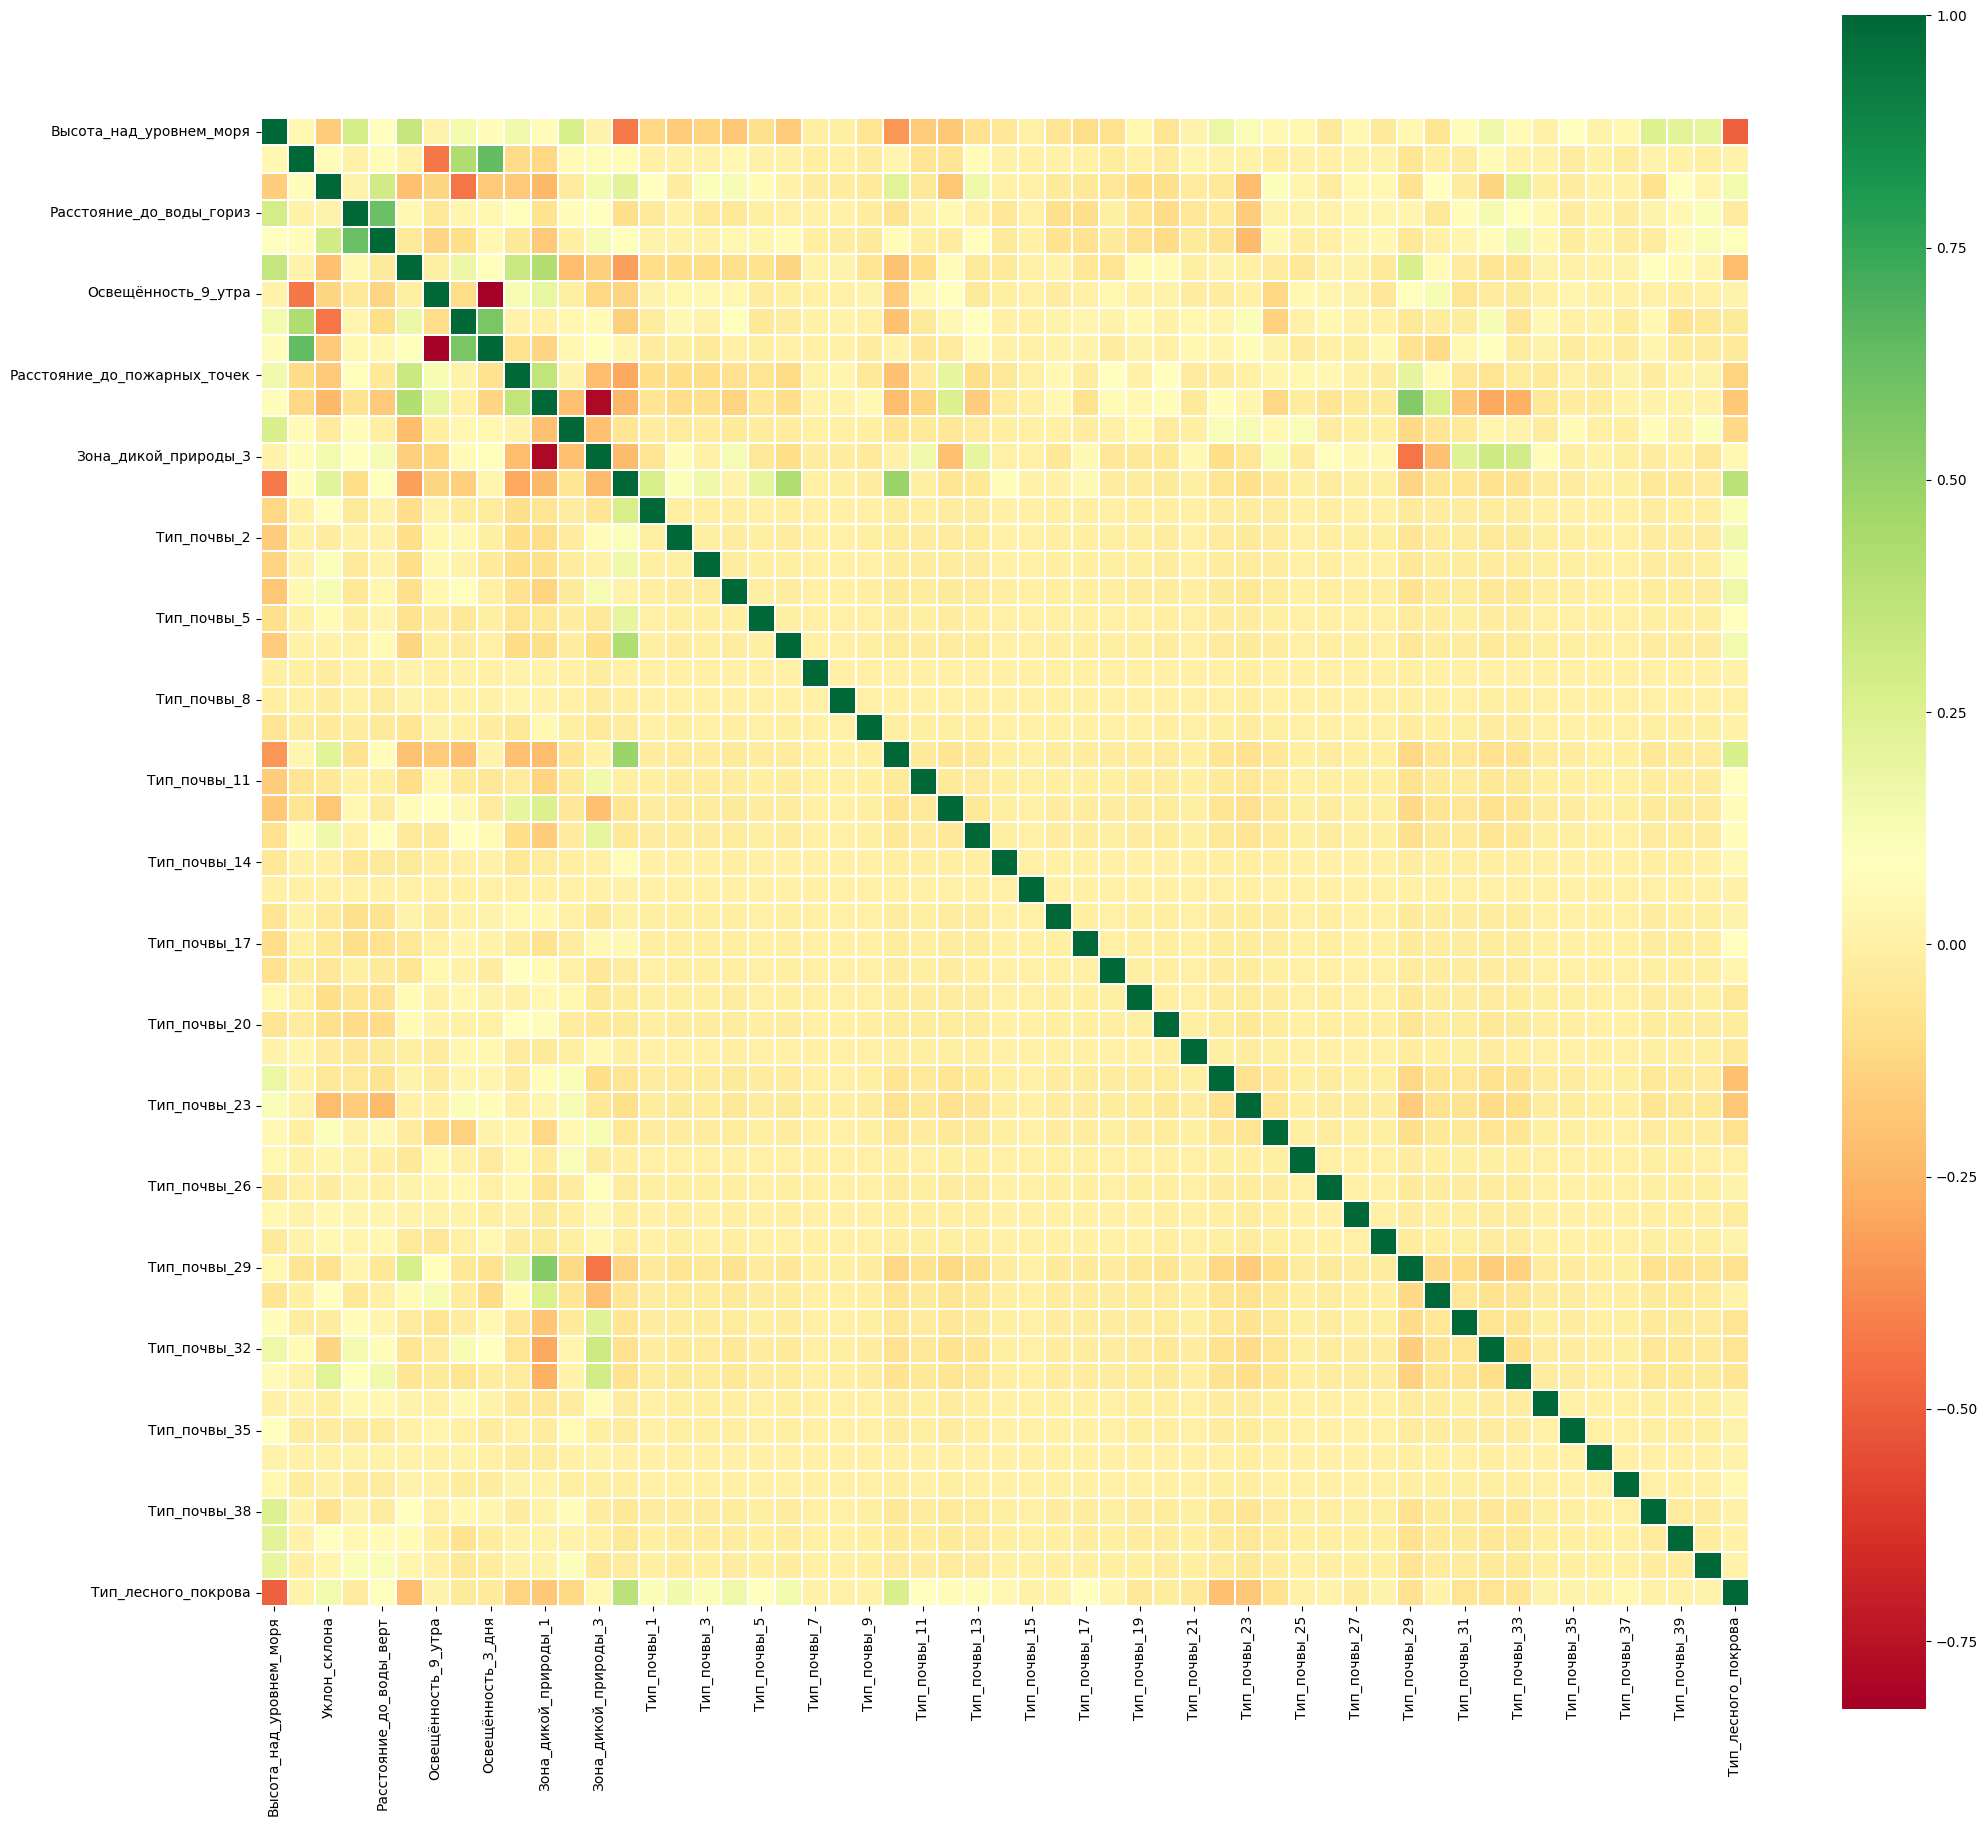

In [6]:
df_corr = pd.concat([X_train, y_train], axis=1)
sns.heatmap(df_corr.corr(method='spearman'), annot=False, cmap='RdYlGn', linewidths=0.2, square=True)
fig = plt.gcf()
fig.set_size_inches(24, 22)
plt.show()

## Анализ

Для проверки вывел матрицу корреляций. Здесь интересны исключительно корреляции признаков с целевой переменной, так как в последствие будут использован метод фильтрации для отбора. Методы фильтрации как раз и занимаются проверкой корреляций для оценки признаков. Как видно по тепловой карте, в основном все признаки обучающей выборки не имеют четкий корреляций с целевой переменной за исключением **Высота_над_уровнем_моря** (отрицательная) и **Зона_дикой_природы_4** (положительная). На основании увиденного можем сделать предварительный вывод о том, что, вероятно, выделенные признаки получат наибольшую оценку при использовании методов фильтрации.

In [7]:
logistic = LogisticRegression(C=1, penalty='l2', solver='lbfgs', n_jobs=-1, random_state=42, max_iter=500).fit(X_train, y_train)
model = SelectFromModel(logistic, prefit=True)

In [8]:
selector_ind = model.get_support()
X_tr_l2 = X_train.iloc[:, selector_ind]
X_ts_l2 = X_test.iloc[:, selector_ind]
print("Отобранные признаки:")
print(X_tr_l2.columns.tolist())
print(f"Осталось признаков: {X_tr_l2.shape[1]} из {X_train.shape[1]}")
X_tr_l2.head()

Отобранные признаки:
['Высота_над_уровнем_моря', 'Освещённость_9_утра', 'Освещённость_3_дня', 'Зона_дикой_природы_1', 'Зона_дикой_природы_2', 'Зона_дикой_природы_3', 'Зона_дикой_природы_4', 'Тип_почвы_1', 'Тип_почвы_2', 'Тип_почвы_3', 'Тип_почвы_4', 'Тип_почвы_12', 'Тип_почвы_13', 'Тип_почвы_20', 'Тип_почвы_22', 'Тип_почвы_26', 'Тип_почвы_31', 'Тип_почвы_32', 'Тип_почвы_33', 'Тип_почвы_37']
Осталось признаков: 20 из 54


,Высота_над_уровнем_моря,Освещённость_9_утра,Освещённость_3_дня,Зона_дикой_природы_1,Зона_дикой_природы_2,Зона_дикой_природы_3,Зона_дикой_природы_4,Тип_почвы_1,Тип_почвы_2,Тип_почвы_3,Тип_почвы_4,Тип_почвы_12,Тип_почвы_13,Тип_почвы_20,Тип_почвы_22,Тип_почвы_26,Тип_почвы_31,Тип_почвы_32,Тип_почвы_33,Тип_почвы_37
0,1.001601,1.153814,-0.930746,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0.301696,0.331584,0.063317,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
2,0.687358,-0.004782,0.769626,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0
3,0.880189,-0.640142,1.005062,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
4,0.426679,-0.528019,0.848105,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0


## Анализ

В качестве первого метода был выбран встроенный на основе L2-регуляризации. Логистическая регрессия обучается на 54 признаках масштабированного датасета, после чего метод `SelectFromModel` выбирает признаки, у которых модуль коэффициента больше или равна среднему значению. Отбор здесь идет непосредственно во время обучения.

В отличие от L1 регуляризация L2 не зануляет коэффициенты. Выбран этот метод здесь эмпирическим методом, так как L2 отрабатывает в разы быстрее, а также отлично работает на небольших количествах признаков в целом (по методичке < сотен), однако и L1 регуляризация ниже затронута.

В результате было удалено 35 признаков, то есть из 54 исходных осталось только 19. Оставшиеся 19 признаков: `Высота_над_уровнем_моря`,`Освещённость_9_утра`,
`Освещённость_3_дня`, все четыре `Зона_дикой_природы` и
`Тип_почвы_(1, 2, 3, 4, 12, 13, 20, 22, 26, 31, 33, 37)`.

Вполне возможно, что было удалено такое болльшое количество признаков потому, что все признаки в целом слабо коррелируют. Следственно, необходимо сравнить данный метод с другими для получения полной картины.

In [9]:
logistic1 = LogisticRegression(C=1, penalty='l1', solver='saga', n_jobs=-1, random_state=42, max_iter=1000).fit(X_train, y_train)
model1 = SelectFromModel(logistic, prefit=True)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [10]:
selector_ind1 = model1.get_support()
X_tr_l1 = X_train.iloc[:, selector_ind1]
X_ts_l1 = X_test.iloc[:, selector_ind1]
print("Отобранные признаки:")
print(X_tr_l1.columns.tolist())
print(f"Осталось признаков: {X_tr_l1.shape[1]} из {X_train.shape[1]}")
X_tr_l1.head()

Отобранные признаки:
['Высота_над_уровнем_моря', 'Освещённость_9_утра', 'Освещённость_3_дня', 'Зона_дикой_природы_1', 'Зона_дикой_природы_2', 'Зона_дикой_природы_3', 'Зона_дикой_природы_4', 'Тип_почвы_1', 'Тип_почвы_2', 'Тип_почвы_3', 'Тип_почвы_4', 'Тип_почвы_12', 'Тип_почвы_13', 'Тип_почвы_20', 'Тип_почвы_22', 'Тип_почвы_26', 'Тип_почвы_31', 'Тип_почвы_32', 'Тип_почвы_33', 'Тип_почвы_37']
Осталось признаков: 20 из 54


,Высота_над_уровнем_моря,Освещённость_9_утра,Освещённость_3_дня,Зона_дикой_природы_1,Зона_дикой_природы_2,Зона_дикой_природы_3,Зона_дикой_природы_4,Тип_почвы_1,Тип_почвы_2,Тип_почвы_3,Тип_почвы_4,Тип_почвы_12,Тип_почвы_13,Тип_почвы_20,Тип_почвы_22,Тип_почвы_26,Тип_почвы_31,Тип_почвы_32,Тип_почвы_33,Тип_почвы_37
0,1.001601,1.153814,-0.930746,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0.301696,0.331584,0.063317,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
2,0.687358,-0.004782,0.769626,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0
3,0.880189,-0.640142,1.005062,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
4,0.426679,-0.528019,0.848105,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0


## Анализ

Получили идентичные с L2 результаты. Увеличенного количества итераций все равно не хватило модели для схождения весов

In [11]:
imp = mutual_info_classif(X_train, y_train, discrete_features=(X_train.nunique() == 2), random_state=42)
feat_imp = pd.Series(imp, X_train.columns)
feat_imp.sort_values(ascending=False)

,0
Высота_над_уровнем_моря,0.457817
Зона_дикой_природы_4,0.146545
Расстояние_до_дорог,0.088114
Расстояние_до_пожарных_точек,0.069951
Зона_дикой_природы_1,0.066792
Тип_почвы_10,0.064091
Уклон_склона,0.035828
Освещённость_9_утра,0.030662
Тип_почвы_38,0.030480
Тип_почвы_29,0.029761


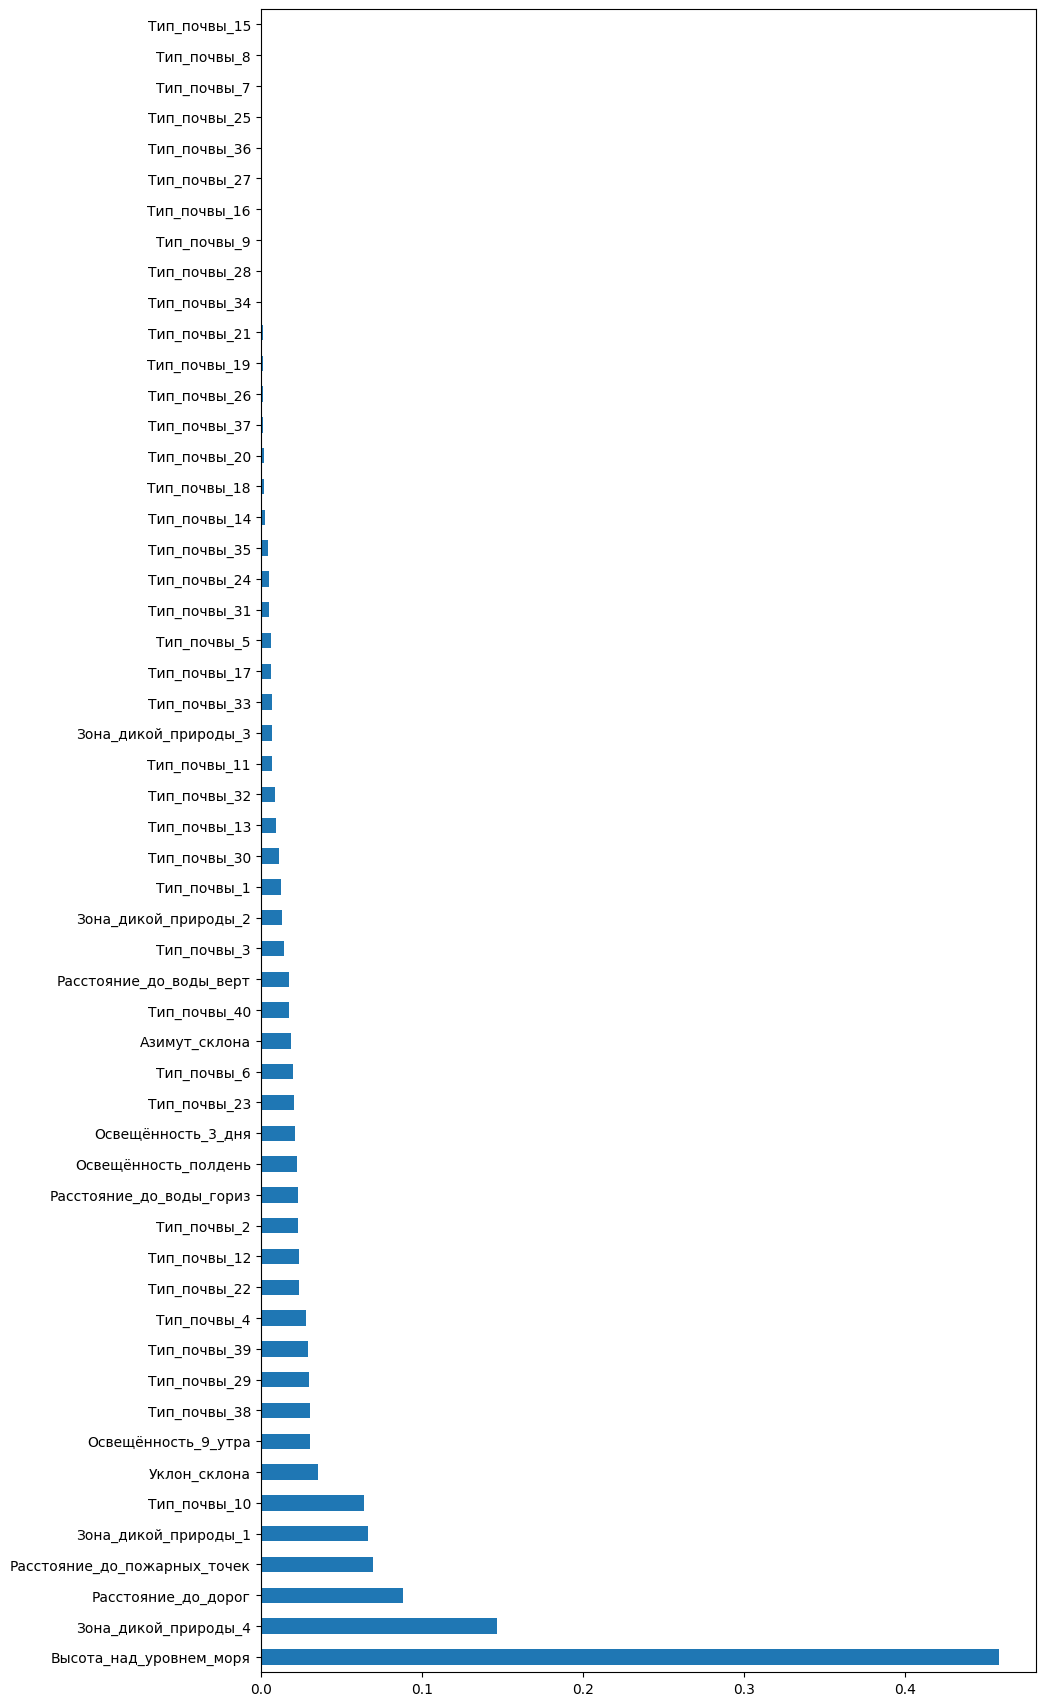

In [12]:
plt.figure(figsize=(10, len(feat_imp) * 0.4))
feat_imp.sort_values(ascending=False).plot(kind='barh')
plt.show()

In [13]:
best = SelectKBest(score_func=mutual_info_classif, k=25)
fit = best.fit(X_train, y_train)

In [14]:
scores = pd.DataFrame(fit.scores_)
columns = pd.DataFrame(X_train.columns)

feat_sc = pd.concat([columns, scores], axis=1)
feat_sc.columns = ['Feat','Score']
print(feat_sc.head(15))

                            Feat     Score
0        Высота_над_уровнем_моря  0.458449
1                  Азимут_склона  0.020165
2                   Уклон_склона  0.035887
3       Расстояние_до_воды_гориз  0.024727
4        Расстояние_до_воды_верт  0.019648
5            Расстояние_до_дорог  0.087464
6            Освещённость_9_утра  0.029791
7           Освещённость_полдень  0.022473
8             Освещённость_3_дня  0.020589
9   Расстояние_до_пожарных_точек  0.069212
10          Зона_дикой_природы_1  0.097218
11          Зона_дикой_природы_2  0.014026
12          Зона_дикой_природы_3  0.030162
13          Зона_дикой_природы_4  0.148557
14                   Тип_почвы_1  0.013462


## Анализ

В качестве второго метода выбран фильтрационный на основе сбора информации. Здесь изначально было рассчитано уменьшение энтропии и составлен график по каждому из признаков, то есть, фактически, рассчитана степень корреляции признаков с целевой переменной в отрыве от других признаков. Видим, что гипотеза, сделанная при просмотре тепловой карты подтвердилась - наибольшую оценку имеют **Высота_над_уровнем_моря** и **Зона_дикой_природы_4**. Также после некоторого числа анализируемых признаков вычесленная оценка резко уменьшается, а для некоторых признаков и вовсе стремится к нулю. На основании этого было выбрано 25 наиболее значащих признаков. Различия по структуре и "побеждающим" признакам здесь существенные, например, непрерывные числовые признаки, связанные с расстоянием здесь, в отличие от регуляризации L2 попали в итоговую выборку, хотя при использовании L1 большую часть выборки занимают бинарные признаки.

Отмечу, что при использовании обоих методов есть риск потерять информативные признаки, так как встроенные методы на основе логистической регрессии может не увидеть важных взаимодействий между признаками, а фильтрация и вовсе не рассматривает подмножества признаков.

Отмечу, что при использовании L1 регуляризации со схожими с L2 параметрами модель вовсе не смогла подобрать оптимальные параметры, поэтому пришлось существенно увеличивать максимальное количество итераций.

Изменение параметров здесь в целом повлияло только на время обучения логистической регрессии в случае с регуляризацией, и на количество выбираемых признаков. Однозначно определить оптимальный вариант не вышло, что согласуется с методичкой. Фильтрация сильно выигравает по скорости, а регуляризация, возможно, по полезным взаимодействиям между признаками, что может положительно сказаться на итоговой выборке при обучении модели.

In [15]:
lr = LogisticRegression(class_weight='balanced', solver='lbfgs', max_iter=500, random_state=42, n_jobs=-1)
rfe = RFE(lr, n_features_to_select=25)
rfe=rfe.fit(X_train, y_train)

In [16]:
sel_rfe = rfe.get_support()
X_tr_rfe = X_train.iloc[:, sel_rfe]
X_ts_rfe = X_test.iloc[:,  sel_rfe]
print(f'RFE (n={25}) отобрал: {X_tr_rfe.shape[1]}')
print(X_tr_rfe.columns.tolist())

RFE (n=25) отобрал: 25
['Высота_над_уровнем_моря', 'Зона_дикой_природы_1', 'Зона_дикой_природы_3', 'Зона_дикой_природы_4', 'Тип_почвы_2', 'Тип_почвы_3', 'Тип_почвы_4', 'Тип_почвы_9', 'Тип_почвы_12', 'Тип_почвы_13', 'Тип_почвы_17', 'Тип_почвы_19', 'Тип_почвы_20', 'Тип_почвы_21', 'Тип_почвы_22', 'Тип_почвы_23', 'Тип_почвы_24', 'Тип_почвы_26', 'Тип_почвы_27', 'Тип_почвы_28', 'Тип_почвы_31', 'Тип_почвы_32', 'Тип_почвы_33', 'Тип_почвы_34', 'Тип_почвы_37']


## Анализ

Последним примененным методом стол метод обертки на основе рекурсивного исключения признаков. В отличие от методов фильтрации данный метод обучает модель на полном наборе признаков и, оценивая коэффициенты, на каждом шаге удаляет самый слабый признак из всех. Набор данных уменьшился с до заданных 25 признаков. Отличие от встроенных методов здесь в том, что для исключения неинформативных признаков здесь используется еще один проход, что замедляет процесс отбора. В набор по итогу попал **Высота_над_уровнем_моря** как самый коррелирующий с целевой переменной признак, а остальная часть распределения занята бинарными признаками. При этом сюда попали 3 из 4 зон дикой природы. Вполне возможно, что на это повлиял параметр `class_weight` и при его смене получим другой результат.

In [17]:
mutual = fit.get_support()
X_tr_m = X_train.iloc[:, mutual]
X_ts_m = X_test.iloc[:,  mutual]

sel_l1 = X_tr_l1.columns.tolist()
sel_l2 = X_tr_l2.columns.tolist()
sel_mut = X_tr_m.columns.tolist()
sel_rfe = X_tr_rfe.columns.tolist()

data = {
    'L1': X_train.columns.isin(sel_l1),
    'L2': X_train.columns.isin(sel_l2),
    'RFE': X_train.columns.isin(sel_rfe),
    'Mutual': X_train.columns.isin(sel_mut)
}

dfmet = pd.DataFrame(data, index=X_train.columns)
dfmet['Total'] = dfmet.sum(axis=1)
dfmet = dfmet.sort_values(by='Total', ascending=False)
print(dfmet)

                                 L1     L2    RFE  Mutual  Total
Высота_над_уровнем_моря        True   True   True    True      4
Тип_почвы_4                    True   True   True    True      4
Тип_почвы_2                    True   True   True    True      4
Зона_дикой_природы_1           True   True   True    True      4
Зона_дикой_природы_4           True   True   True    True      4
Зона_дикой_природы_3           True   True   True    True      4
Тип_почвы_22                   True   True   True    True      4
Тип_почвы_12                   True   True   True    True      4
Тип_почвы_3                    True   True   True   False      3
Зона_дикой_природы_2           True   True  False    True      3
Тип_почвы_13                   True   True   True   False      3
Тип_почвы_20                   True   True   True   False      3
Освещённость_3_дня             True   True  False    True      3
Освещённость_9_утра            True   True  False    True      3
Тип_почвы_26             

## Анализ

Будем рассматривать 4 примененных методов отбора признаков. Распределение по числу голосов показало, что в выборке имеются как устойчивые признаки, попавшие в подмножества всех четырех методов, так и неустойчивые. Кроме того, в некоторых областях таблицы наблюдается группирование с учетом того, что оба метода регуляризации дали идентичные результаты. В финальный датасет будем брать только столбцы, которые попали в выборке 3 или более методов, так как они, судя по статистике являются наиболее информативными.

In [27]:
fin_m = dfmet[dfmet['Total'] >= 3].index.tolist()
fin_s = [col for col in X_train.columns if col.startswith('Тип_почвы_')]
fin_w = [col for col in X_train.columns if col.startswith('Зона_дикой_природы')]
fin = list(dict.fromkeys(fin_m + fin_s + fin_w))

X_train_f = X_train[fin].copy()
X_test_f = X_test[fin].copy()

print(f"NaN в train: {X_train_f.isnull().sum().sum()}")
print(f"NaN в test: {X_test_f.isnull().sum().sum()}")

train_out = X_train_f.copy()
train_out['Тип_лесного_покрова'] = y_train.values
test_out = X_test_f.copy()
test_out['Тип_лесного_покрова'] = y_test.values

NaN в train: 0
NaN в test: 0


In [28]:
print(f"Train до: {X_train.shape}\tпосле: {X_train_f.shape}")
print(f"Test до: {X_test.shape}\tпосле: {X_test_f.shape}")

Train до: (464772, 54)	после: (464772, 47)
Test до: (116194, 54)	после: (116194, 47)


In [29]:
train_out.columns

Index(['Высота_над_уровнем_моря', 'Тип_почвы_4', 'Тип_почвы_2',
       'Зона_дикой_природы_1', 'Зона_дикой_природы_4', 'Зона_дикой_природы_3',
       'Тип_почвы_22', 'Тип_почвы_12', 'Тип_почвы_3', 'Зона_дикой_природы_2',
       'Тип_почвы_13', 'Тип_почвы_20', 'Освещённость_3_дня',
       'Освещённость_9_утра', 'Тип_почвы_26', 'Тип_почвы_32', 'Тип_почвы_31',
       'Тип_почвы_33', 'Тип_почвы_37', 'Тип_почвы_1', 'Тип_почвы_5',
       'Тип_почвы_6', 'Тип_почвы_7', 'Тип_почвы_8', 'Тип_почвы_9',
       'Тип_почвы_10', 'Тип_почвы_11', 'Тип_почвы_14', 'Тип_почвы_15',
       'Тип_почвы_16', 'Тип_почвы_17', 'Тип_почвы_18', 'Тип_почвы_19',
       'Тип_почвы_21', 'Тип_почвы_23', 'Тип_почвы_24', 'Тип_почвы_25',
       'Тип_почвы_27', 'Тип_почвы_28', 'Тип_почвы_29', 'Тип_почвы_30',
       'Тип_почвы_34', 'Тип_почвы_35', 'Тип_почвы_36', 'Тип_почвы_38',
       'Тип_почвы_39', 'Тип_почвы_40', 'Тип_лесного_покрова'],
      dtype='object')

In [33]:
train_out.head()

,Высота_над_уровнем_моря,Тип_почвы_4,Тип_почвы_2,Зона_дикой_природы_1,Зона_дикой_природы_4,Зона_дикой_природы_3,Тип_почвы_22,Тип_почвы_12,Тип_почвы_3,Зона_дикой_природы_2,...,Тип_почвы_28,Тип_почвы_29,Тип_почвы_30,Тип_почвы_34,Тип_почвы_35,Тип_почвы_36,Тип_почвы_38,Тип_почвы_39,Тип_почвы_40,Тип_лесного_покрова
0,1.001601,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
1,0.301696,0,0,1,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,2
2,0.687358,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,2
3,0.880189,0,0,0,0,0,1,0,0,1,...,0,0,0,0,0,0,0,0,0,1
4,0.426679,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,2


In [34]:
train_out.to_csv('covtype-7-s.csv', index=False)
test_out.to_csv('covtype-7-test-s.csv', index=False)

## Итоговый вывод. Связный текст

В сквозном пайплайне отбор признаков это отдельный этап обработки данных, на котором происходит удаление нерелевантных и неинформативных стобцов. Здесь не меняются значения и не удаляются записи, снижается только количество признаков, а следственно и вычислительная сложность. К тому же удаление мусорных фич позволяет снизить риск переобучения и сохранить обобщающую способность. В данной работе были применены четыре метода отбора: два встроенных - L1 и L2 регуляризация, обертка - рекурсивное исключение признаков и фильтрация на основе сбора информации. Все использованные методы по-разному решают проблему отбора наиболее информативных признаков, поэтому рассматривать их в отрыве друг от друга и использовать единственный метод не является правильным решением. При использовании встроенных методов были выбраны стандартные параметры, указанные в методических указаниях, однако при L1 регуляризации был использован `solver='saga'`, так как он единственный полностью поддерживает ее на задаче для 7 классов. Здесь стоит указать, что регуляризация обоими методами дала идентичный результат в виде 19 одинаковых признаков. При использовании методов обертки и фильтрации опора была именно на результаты регуляризации, а также на эмпирические результаты после составления графика и тепловой карты по матрице корреляций. В итоговый набор данных попали 17 из 54 изначальных столбцов, девять из которых полностью согласованы всеми четырьмя методами. Были удалены все шумные, у которых не подтвердилось влияние на целевую переменную ни одним из методов, а также маловероятные стобцы. Судя по результатам отбора итоговый датасет подходит для следующих работ, потому что в нем сохранились действительно информативные признаки, которые не будет вносить шум в процессе обучения, а размерность полностью покроет многие алгоритмы машинного обучения.
